# Distinguishing Malignant from Benign Breast Tumours using Cell-Nucleus Measurements
**CES 2103 – Data Analytics | IA3 Mini Project | EDA + CDA on the Wisconsin Diagnostic Breast Cancer (WDBC) dataset**

Team number: 12  
Members:  
Vani Mallya - 251090050006  
Anoothi Nayar - 251090050019  
Prabhanjana Joshi - 251090050046  
Shailja Jhajharia - 251090051214   
Date: 25 October 2026

**Research questions (CDA):**  
1. Do malignant and benign breast masses differ in the average size (radius) of their cell nuclei? *(Welch t-test)*  
2. Is diagnosis associated with the level of nuclear boundary irregularity (high vs low mean concave points)? *(chi-square test of independence)*

**Notebook map:** Dataset source → Preprocessing → EDA → CDA 1 (Welch t-test) → CDA 2 (chi-square test) → Supporting analyses → Findings

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score, confusion_matrix, accuracy_score

os.makedirs("figures", exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
PAL = {"Malignant": "#C0392B", "Benign": "#2E86AB"}
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
print("Setup complete")

Setup complete


## 1. Dataset source and description
* **Name:** Breast Cancer Wisconsin (Diagnostic) – WDBC  
* **Source:** UCI Machine Learning Repository (id 17), https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic , DOI 10.24432/C5DW2B. Creators: W. H. Wolberg, W. N. Street, O. L. Mangasarian (University of Wisconsin, 1993). Licence: CC BY 4.0.  
* **How it was obtained for this project:** the identical 569-row copy distributed inside scikit-learn (`sklearn.datasets.load_breast_cancer`), exported unchanged to `data/raw_wdbc.csv` (the patient-ID column of the UCI file is not part of the scikit-learn copy).  
* **Unit of observation:** one fine-needle-aspirate (FNA) image of a breast mass. A digitised image was segmented and the nuclei outlines were measured by computer; each row summarises one patient's mass.  
* **Variables:** 10 nucleus characteristics (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (mean of the three largest values) = 30 numeric features. Outcome: **diagnosis** (malignant / benign, confirmed by biopsy follow-up).

In [2]:
from sklearn.datasets import load_breast_cancer
bunch = load_breast_cancer(as_frame=True)
raw = bunch.frame.copy()                       # 30 features + 'target' (0 = malignant, 1 = benign)
raw.to_csv("data/raw_wdbc.csv", index=False)   # raw, unmodified export
print("Raw shape:", raw.shape)
print("Target coding in source:", {str(k): v for k, v in zip(bunch.target_names, [0, 1])})
raw.head()

Raw shape: (569, 31)
Target coding in source: {'malignant': 0, 'benign': 1}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
raw = pd.read_csv("data/raw_wdbc.csv")
print(raw.dtypes.value_counts())
raw.describe().T.round(3).head(10)

float64    30
int64       1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## 2. Data preprocessing
Steps performed (and the evidence for each): schema/dtype check → missing values → duplicates → impossible values and valid zeros → outliers (IQR rule) → skewness and transformation → multicollinearity → label decoding and derived features → scaling (inside models only).

In [4]:
df = raw.copy()

# 2.1 Structure, missing values, duplicates
print("Rows x columns:", df.shape)
print("All numeric:", all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes))
print("Missing values (total):", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate feature vectors ignoring label:", int(df.drop(columns='target').duplicated().sum()))

Rows x columns: (569, 31)
All numeric: True
Missing values (total): 0
Exact duplicate rows: 0
Duplicate feature vectors ignoring label: 0


In [5]:
# 2.2 Range / validity checks (physical impossibilities)
size_cols = [c for c in df.columns if any(k in c for k in ["radius", "perimeter", "area", "texture"])]
print("Non-positive size/texture values:", int((df[size_cols] <= 0).sum().sum()))
print("Negative values anywhere:", int((df.drop(columns='target') < 0).sum().sum()))

zero_counts = (df.drop(columns='target') == 0).sum()
print("\nColumns containing zeros:")
print(zero_counts[zero_counts > 0])
print("\nZeros occur only in concavity / concave-point measures, where 0 means a perfectly convex "
      "outline (no concave portions). They are valid, so they are kept (and a log1p-type transform is avoided there).")
print("Label of rows with mean concavity == 0:", df.loc[df['mean concavity'] == 0, 'target'].map({0: 'Malignant', 1: 'Benign'}).value_counts().to_dict())

Non-positive size/texture values: 0
Negative values anywhere: 0

Columns containing zeros:
mean concavity          13
mean concave points     13
concavity error         13
concave points error    13
worst concavity         13
worst concave points    13
dtype: int64

Zeros occur only in concavity / concave-point measures, where 0 means a perfectly convex outline (no concave portions). They are valid, so they are kept (and a log1p-type transform is avoided there).
Label of rows with mean concavity == 0: {'Benign': 13}


In [6]:
# 2.3 Outliers with the IQR rule (1.5 x IQR) on the 10 'mean' features
mean_cols = [c for c in df.columns if c.startswith("mean ")]
rows = []
for c in mean_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df[(df[c] < lo) | (df[c] > hi)]
    rows.append([c, len(out), round(100*len(out)/len(df), 1), round(100*(out['target'] == 0).mean(), 1) if len(out) else np.nan])
outliers = pd.DataFrame(rows, columns=["feature", "n_outliers", "pct_rows", "pct_malignant_among_outliers"])
print(outliers.to_string(index=False))
print("\nRows flagged in >=1 mean feature:",
      int(((df[mean_cols] < df[mean_cols].quantile(.25) - 1.5*(df[mean_cols].quantile(.75)-df[mean_cols].quantile(.25))) |
           (df[mean_cols] > df[mean_cols].quantile(.75) + 1.5*(df[mean_cols].quantile(.75)-df[mean_cols].quantile(.25)))).any(axis=1).sum()))
print("Decision: retained - extreme values are mostly large malignant tumours (clinically genuine), not entry errors.")

               feature  n_outliers  pct_rows  pct_malignant_among_outliers
           mean radius          14       2.5                         100.0
          mean texture           7       1.2                          71.4
        mean perimeter          13       2.3                         100.0
             mean area          25       4.4                         100.0
       mean smoothness           6       1.1                          50.0
      mean compactness          16       2.8                         100.0
        mean concavity          18       3.2                          83.3
   mean concave points          10       1.8                         100.0
         mean symmetry          15       2.6                          60.0
mean fractal dimension          15       2.6                          33.3

Rows flagged in >=1 mean feature: 67
Decision: retained - extreme values are mostly large malignant tumours (clinically genuine), not entry errors.


In [7]:
# 2.4 Skewness and transformation
skew_before = df[mean_cols].apply(stats.skew).round(2)
print(skew_before.sort_values(ascending=False).head(6))
df["log_mean_area"] = np.log(df["mean area"])
print("\nmean area skewness: raw = %.2f  ->  log = %.2f" % (stats.skew(df['mean area']), stats.skew(df['log_mean_area'])))
df["log_mean_radius"] = np.log(df["mean radius"])
print("mean radius skewness: raw = %.2f  ->  log = %.2f" % (stats.skew(df['mean radius']), stats.skew(df['log_mean_radius'])))

mean area                 1.64
mean concavity            1.40
mean fractal dimension    1.30
mean compactness          1.19
mean concave points       1.17
mean perimeter            0.99
dtype: float64

mean area skewness: raw = 1.64  ->  log = 0.28
mean radius skewness: raw = 0.94  ->  log = 0.31


In [8]:
# 2.5 Multicollinearity: radius, perimeter and area measure the same thing (size)
corr_size = df[["mean radius", "mean perimeter", "mean area"]].corr().round(3)
print(corr_size)
corr_all = df.drop(columns=["target", "log_mean_area", "log_mean_radius"]).corr().abs()
upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
pairs = upper.stack().dropna().sort_values(ascending=False)
print("\nFeature pairs with |r| > 0.95:", int((pairs > 0.95).sum()), "of", len(pairs))
print(pairs.head(5).round(3))
print("\nDecision: keep all 30 columns in the cleaned file; for modelling, rely on standardisation + regularised logistic regression / PCA, "
      "and treat radius, perimeter and area as one 'size' construct in interpretation.")

                mean radius  mean perimeter  mean area
mean radius           1.000           0.998      0.987
mean perimeter        0.998           1.000      0.987
mean area             0.987           0.987      1.000

Feature pairs with |r| > 0.95: 15 of 435
mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64

Decision: keep all 30 columns in the cleaned file; for modelling, rely on standardisation + regularised logistic regression / PCA, and treat radius, perimeter and area as one 'size' construct in interpretation.


In [9]:
# 2.6 Label decoding and derived features
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"}).astype("category")
df["is_malignant"] = (df["target"] == 0).astype(int)
df["size_group"] = pd.qcut(df["mean radius"], q=3, labels=["Small", "Medium", "Large"])
df["concavity_flag"] = np.where(df["mean concave points"] > df["mean concave points"].median(), "High", "Low")
df["texture_group"] = pd.cut(df["mean texture"], bins=[0, 15, 20, 25, 100], labels=["<15", "15-20", "20-25", ">25"])

clean = df.copy()
clean.to_csv("data/cleaned_wdbc.csv", index=False)
print("Cleaned shape:", clean.shape, "| derived columns:", [c for c in clean.columns if c not in raw.columns])
summary = pd.DataFrame({
    "Aspect": ["Records", "Columns", "Missing values", "Duplicates", "Outliers", "Skewness of mean area"],
    "Before": [raw.shape[0], raw.shape[1], 0, 0, "-", round(stats.skew(raw['mean area']), 2)],
    "After": [clean.shape[0], clean.shape[1], 0, 0, "retained (valid)", round(stats.skew(clean['log_mean_area']), 2)]})
summary

Cleaned shape: (569, 38) | derived columns: ['log_mean_area', 'log_mean_radius', 'diagnosis', 'is_malignant', 'size_group', 'concavity_flag', 'texture_group']


,Aspect,Before,After
0,Records,569,569
1,Columns,31,38
2,Missing values,0,0
3,Duplicates,0,0
4,Outliers,-,retained (valid)
5,Skewness of mean area,1.64,0.28


## 3. Exploratory Data Analysis (EDA)
### 3.1 Descriptive statistics

In [10]:
clean = pd.read_csv("data/cleaned_wdbc.csv")
clean["diagnosis"] = pd.Categorical(clean["diagnosis"], categories=["Malignant", "Benign"])
clean["size_group"] = pd.Categorical(clean["size_group"], categories=["Small", "Medium", "Large"], ordered=True)
clean["texture_group"] = pd.Categorical(clean["texture_group"], categories=["<15", "15-20", "20-25", ">25"], ordered=True)
key = ["mean radius", "mean texture", "mean area", "mean smoothness", "mean concavity", "mean concave points"]

desc = clean[key].agg(["mean", "median", "std", "min", "max"]).T
desc["skew"] = clean[key].apply(stats.skew)
desc["CV %"] = 100 * desc["std"] / desc["mean"]
print("Overall\n", desc.round(3).to_string())

print("\nClass balance:")
cb = clean["diagnosis"].value_counts()
print(pd.DataFrame({"n": cb, "%": (100*cb/len(clean)).round(1)}))

by = clean.groupby("diagnosis", observed=True)[key].agg(["mean", "median"]).round(3)
by

Overall
                         mean   median      std      min       max   skew    CV %
mean radius           14.127   13.370    3.524    6.981    28.110  0.940  24.945
mean texture          19.290   18.840    4.301    9.710    39.280  0.649  22.297
mean area            654.889  551.100  351.914  143.500  2501.000  1.641  53.736
mean smoothness        0.096    0.096    0.014    0.053     0.163  0.455  14.595
mean concavity         0.089    0.062    0.080    0.000     0.427  1.397  89.775
mean concave points    0.049    0.034    0.039    0.000     0.201  1.168  79.320

Class balance:
             n     %
diagnosis           
Benign     357  62.7
Malignant  212  37.3


mean radius         mean texture        mean area         \
                 mean  median         mean median      mean median   
diagnosis                                                            
Malignant      17.463  17.325       21.605  21.46   978.376  932.0   
Benign         12.147  12.200       17.915  17.39   462.790  458.4   

          mean smoothness        mean concavity        mean concave points  \
                     mean median           mean median                mean   
diagnosis                                                                    
Malignant           0.103  0.102          0.161  0.151               0.088   
Benign              0.092  0.091          0.046  0.037               0.026   

                  
          median  
diagnosis         
Malignant  0.086  
Benign     0.023

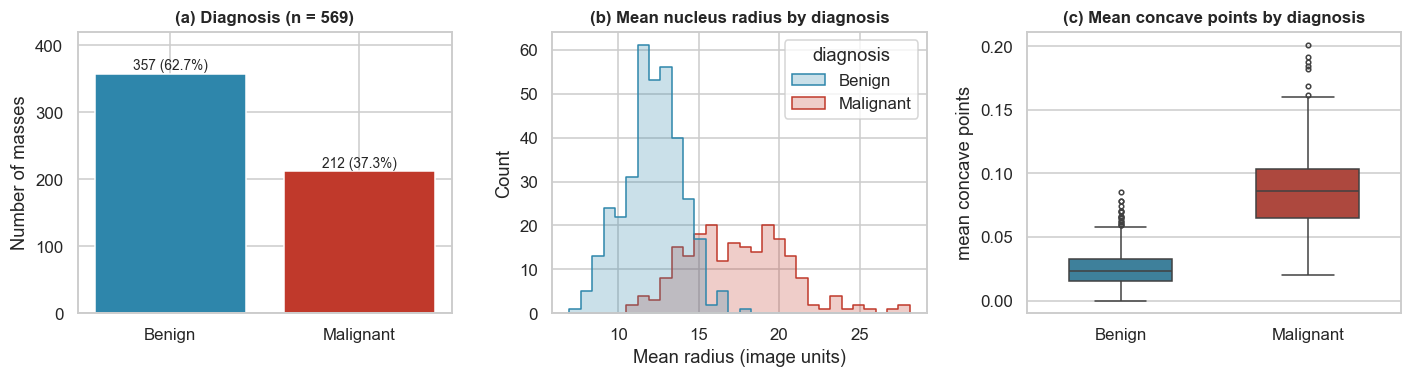

In [13]:
# Figure 1 - class balance + distribution of the key size variable
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cnt = clean["diagnosis"].value_counts().reindex(["Benign", "Malignant"])
bars = ax[0].bar(cnt.index, cnt.values, color=[PAL[k] for k in cnt.index])
for b_, v in zip(bars, cnt.values): ax[0].text(b_.get_x()+b_.get_width()/2, v+6, f"{v} ({100*v/len(clean):.1f}%)", ha="center", fontsize=9)
ax[0].set_title("(a) Diagnosis (n = 569)"); ax[0].set_ylabel("Number of masses"); ax[0].set_ylim(0, 420)

sns.histplot(data=clean, x="mean radius", hue="diagnosis", palette=PAL, bins=30, element="step", stat="count", ax=ax[1], hue_order=["Benign", "Malignant"])
ax[1].set_title("(b) Mean nucleus radius by diagnosis"); ax[1].set_xlabel("Mean radius (image units)")

sns.boxplot(data=clean, x="diagnosis", y="mean concave points", order=["Benign", "Malignant"], palette=PAL, ax=ax[2], width=.55, fliersize=3)
ax[2].set_title("(c) Mean concave points by diagnosis"); ax[2].set_xlabel("")
plt.tight_layout()
plt.savefig("figures/fig1_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.2 Bivariate and multivariate analysis

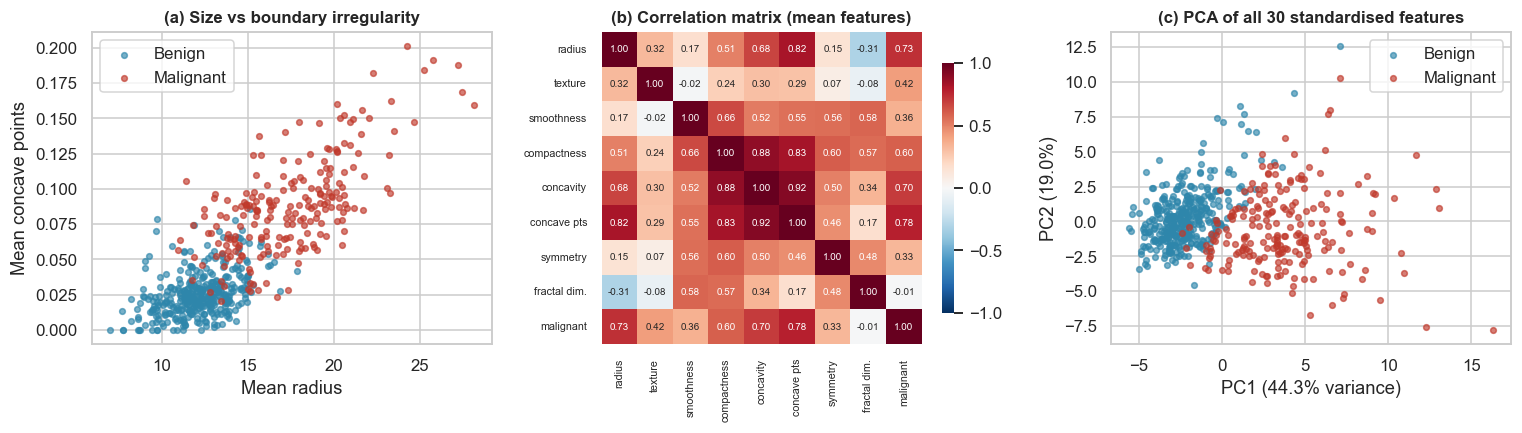

Cumulative variance explained by first 2 / 5 / 10 PCs: 63.2% / 84.7% / 95.2%
r(mean radius, malignant) = 0.730 ; r(mean concave points, malignant) = 0.777 ; r(mean radius, mean perimeter) = 0.998


In [ ]:
# Figure 2 - size vs shape scatter, correlation heatmap, PCA
fig, ax = plt.subplots(1, 3, figsize=(14, 4.1))
for lab in ["Benign", "Malignant"]:
    s = clean[clean.diagnosis == lab]
    ax[0].scatter(s["mean radius"], s["mean concave points"], s=14, alpha=.65, color=PAL[lab], label=lab)
ax[0].set_xlabel("Mean radius"); ax[0].set_ylabel("Mean concave points"); ax[0].set_title("(a) Size vs boundary irregularity"); ax[0].legend(frameon=True)

hm_cols = ["mean radius", "mean texture", "mean smoothness", "mean compactness", "mean concavity", "mean concave points", "mean symmetry", "mean fractal dimension"]
cm = clean[hm_cols + ["is_malignant"]].corr()
short = [c.replace("mean ", "").replace("fractal dimension", "fractal dim.").replace("concave points", "concave pts") for c in hm_cols] + ["malignant"]
sns.heatmap(cm.values, xticklabels=short, yticklabels=short, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 6.5}, cbar_kws={"shrink": .8}, ax=ax[1])
ax[1].set_title("(b) Correlation matrix (mean features)"); ax[1].tick_params(labelsize=7)

X = clean[[c for c in raw.columns if c != "target"]]
Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED).fit(Z); P = pca.transform(Z)
for lab in ["Benign", "Malignant"]:
    m_ = (clean.diagnosis == lab).values
    ax[2].scatter(P[m_, 0], P[m_, 1], s=14, alpha=.65, color=PAL[lab], label=lab)
ax[2].set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% variance)"); ax[2].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)")
ax[2].set_title("(c) PCA of all 30 standardised features"); ax[2].legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/fig2_relationships.png", dpi=200, bbox_inches="tight")
plt.show()

full_pca = PCA().fit(Z)
print("Cumulative variance explained by first 2 / 5 / 10 PCs: %.1f%% / %.1f%% / %.1f%%" % tuple(100*np.cumsum(full_pca.explained_variance_ratio_)[[1, 4, 9]]))
print("r(mean radius, malignant) = %.3f ; r(mean concave points, malignant) = %.3f ; r(mean radius, mean perimeter) = %.3f" % (
    cm.loc['mean radius', 'is_malignant'], cm.loc['mean concave points', 'is_malignant'], clean['mean radius'].corr(clean['mean perimeter'])))

In [13]:
# Malignancy rate by derived groups (categorical EDA)
t1 = clean.groupby("size_group", observed=True)["is_malignant"].agg(["count", "sum", "mean"]).rename(columns={"sum": "malignant", "mean": "malignant_rate"})
t1["malignant_rate"] = (100*t1["malignant_rate"]).round(1)
t2 = clean.groupby("concavity_flag")["is_malignant"].agg(["count", "sum", "mean"]).rename(columns={"sum": "malignant", "mean": "malignant_rate"})
t2["malignant_rate"] = (100*t2["malignant_rate"]).round(1)
t3 = clean.groupby("texture_group", observed=True)["is_malignant"].agg(["count", "sum", "mean"]).rename(columns={"sum": "malignant", "mean": "malignant_rate"})
t3["malignant_rate"] = (100*t3["malignant_rate"]).round(1)
print("By mean-radius tercile\n", t1, "\n\nBy mean concave points (median split)\n", t2, "\n\nBy mean texture band\n", t3)

By mean-radius tercile
             count  malignant  malignant_rate
size_group                                  
Small         191          6             3.1
Medium        188         39            20.7
Large         190        167            87.9 

By mean concave points (median split)
                 count  malignant  malignant_rate
concavity_flag                                  
High              284        201            70.8
Low               285         11             3.9 

By mean texture band
                count  malignant  malignant_rate
texture_group                                  
<15               91          4             4.4
15-20            253         66            26.1
20-25            169        110            65.1
>25               56         32            57.1


Features with |d| >= 0.8: 20 of 30 | |d| < 0.2: 5
{'worst concave points': 2.69, 'worst perimeter': 2.6, 'mean concave points': 2.55, 'worst radius': 2.54, 'mean perimeter': 2.29}


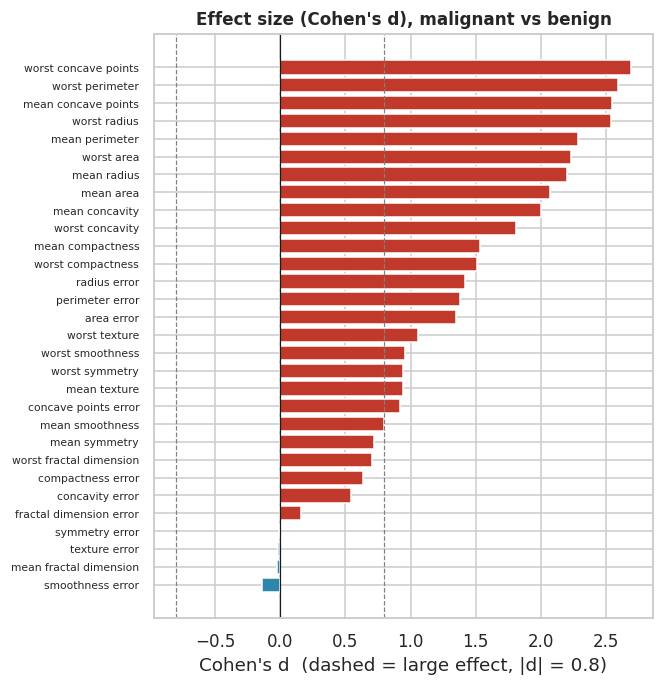

In [14]:
# Effect-size ranking of all 30 features (Cohen's d, malignant minus benign) - EDA only, tested formally in 6.1
def cohens_d(a, b):
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / sp
mal, ben = clean[clean.is_malignant == 1], clean[clean.is_malignant == 0]
d_all = pd.Series({c: cohens_d(mal[c], ben[c]) for c in X.columns}).sort_values()
fig, ax = plt.subplots(figsize=(6.2, 6.4))
ax.barh(d_all.index, d_all.values, color=np.where(d_all.values > 0, PAL["Malignant"], PAL["Benign"]))
ax.axvline(0, color="k", lw=.8); ax.axvline(.8, color="grey", ls="--", lw=.8); ax.axvline(-.8, color="grey", ls="--", lw=.8)
ax.set_title("Effect size (Cohen's d), malignant vs benign"); ax.set_xlabel("Cohen's d  (dashed = large effect, |d| = 0.8)"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig("figures/fig_effect_sizes.png", dpi=200, bbox_inches="tight"); plt.show()
print("Features with |d| >= 0.8:", int((d_all.abs() >= .8).sum()), "of 30 | |d| < 0.2:", int((d_all.abs() < .2).sum()))
print(d_all.abs().sort_values(ascending=False).head(5).round(2).to_dict())

**EDA observations**
1. Classes are moderately imbalanced: 62.7% benign, 37.3% malignant.
2. Malignant nuclei are larger and more irregular: median mean-radius ≈ 17.3 vs 12.2, and the distributions overlap only slightly.
3. Radius, perimeter and area are almost perfectly collinear (r > 0.98); concavity, concave points and compactness form a second correlated "irregularity" block.
4. Two principal components already separate the classes visually, so a few shape/size features carry most of the signal.
5. Texture-error, smoothness-error, symmetry-error and fractal-dimension features barely differ between classes.

## 4. CDA 1 – Do malignant and benign masses differ in mean nucleus radius? (Welch t-test)
### 4.1 Research question and hypotheses
**Research question 1:** Do malignant and benign breast masses differ in mean nucleus radius?

* **H₀:** μ(malignant) = μ(benign) – no difference in mean "mean radius".
* **H₁:** μ(malignant) ≠ μ(benign) (two-sided).
* **Significance level:** α = 0.05.

### 4.2 Choice of test and assumption checks
`mean radius` is numeric; diagnosis defines two **independent** groups (one mass per patient row). We therefore use an independent two-sample t-test. Normality and equal variance are checked first.

In [15]:
a = clean.loc[clean.is_malignant == 1, "mean radius"].values   # malignant
b = clean.loc[clean.is_malignant == 0, "mean radius"].values   # benign
print(f"n malignant = {len(a)}, n benign = {len(b)}")
print(f"Malignant: mean {a.mean():.3f}, SD {a.std(ddof=1):.3f}, median {np.median(a):.3f}")
print(f"Benign   : mean {b.mean():.3f}, SD {b.std(ddof=1):.3f}, median {np.median(b):.3f}")

sw_a, sw_b = stats.shapiro(a), stats.shapiro(b)
lev = stats.levene(a, b, center="median")
print(f"\nShapiro-Wilk malignant: W = {sw_a.statistic:.4f}, p = {sw_a.pvalue:.4g}")
print(f"Shapiro-Wilk benign   : W = {sw_b.statistic:.4f}, p = {sw_b.pvalue:.4g}")
print(f"Levene (Brown-Forsythe): W = {lev.statistic:.2f}, p = {lev.pvalue:.4g}")
print(f"Skewness: malignant {stats.skew(a):.2f}, benign {stats.skew(b):.2f}")
print("\n-> Groups are slightly non-normal and variances differ, so Welch's t-test is used (no equal-variance assumption);")
print("   with n >= 212 per group the Central Limit Theorem makes the mean approximately normal.")
print("   Mann-Whitney U, a permutation test and a bootstrap CI are run as distribution-free robustness checks.")

n malignant = 212, n benign = 357
Malignant: mean 17.463, SD 3.204, median 17.325
Benign   : mean 12.147, SD 1.781, median 12.200

Shapiro-Wilk malignant: W = 0.9777, p = 0.001895
Shapiro-Wilk benign   : W = 0.9967, p = 0.668
Levene (Brown-Forsythe): W = 90.48, p = 5.28e-20
Skewness: malignant 0.50, benign -0.08

-> Groups are slightly non-normal and variances differ, so Welch's t-test is used (no equal-variance assumption);
   with n >= 212 per group the Central Limit Theorem makes the mean approximately normal.
   Mann-Whitney U, a permutation test and a bootstrap CI are run as distribution-free robustness checks.


In [16]:
# 4.3 Primary test: Welch's t-test
tw = stats.ttest_ind(a, b, equal_var=False)
va, vb = a.var(ddof=1)/len(a), b.var(ddof=1)/len(b)
df_w = (va + vb)**2 / (va**2/(len(a)-1) + vb**2/(len(b)-1))
diff = a.mean() - b.mean(); se = np.sqrt(va + vb)
tcrit = stats.t.ppf(.975, df_w); ci_w = (diff - tcrit*se, diff + tcrit*se)
sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
d = diff / sp
g = d * (1 - 3/(4*(len(a)+len(b)) - 9))      # Hedges' small-sample correction
print(f"Welch t = {tw.statistic:.2f}, df = {df_w:.1f}, p = {tw.pvalue:.3g}")
print(f"Mean difference (malignant - benign) = {diff:.3f}, 95% CI [{ci_w[0]:.3f}, {ci_w[1]:.3f}]")
print(f"Cohen's d = {d:.2f}, Hedges' g = {g:.2f}  (large: > 0.8)")
print("Decision at alpha = 0.05:", "REJECT H0" if tw.pvalue < .05 else "FAIL TO REJECT H0")

Welch t = 22.21, df = 289.7, p = 1.68e-64
Mean difference (malignant - benign) = 5.316, 95% CI [4.845, 5.787]
Cohen's d = 2.21, Hedges' g = 2.20  (large: > 0.8)
Decision at alpha = 0.05: REJECT H0


In [17]:
# 4.4 Robustness checks
mw = stats.mannwhitneyu(a, b, alternative="two-sided")
cles = mw.statistic / (len(a)*len(b))                      # P(malignant radius > benign radius)
r_rb = 2*cles - 1                                          # rank-biserial correlation
print(f"Mann-Whitney U = {mw.statistic:.0f}, p = {mw.pvalue:.3g}; P(random malignant > random benign) = {cles:.3f}; rank-biserial r = {r_rb:.3f}")

pooled = np.concatenate([a, b]); B = 10000
perm_diffs = np.empty(B)
for i in range(B):
    rng.shuffle(pooled)
    perm_diffs[i] = pooled[:len(a)].mean() - pooled[len(a):].mean()
p_perm = (np.sum(np.abs(perm_diffs) >= abs(diff)) + 1) / (B + 1)
print(f"Permutation test ({B:,} shuffles): observed diff = {diff:.3f}, largest |shuffled diff| = {np.abs(perm_diffs).max():.3f}, p = {p_perm:.4g}")

boot = np.array([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(5000)])
ci_b = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap (5,000 resamples) 95% CI of mean difference: [{ci_b[0]:.3f}, {ci_b[1]:.3f}]")

# ratio on log scale (geometric means) as a multiplicative effect
tl = stats.ttest_ind(np.log(a), np.log(b), equal_var=False)
dl = np.log(a).mean() - np.log(b).mean(); sel = np.sqrt(np.log(a).var(ddof=1)/len(a) + np.log(b).var(ddof=1)/len(b))
print(f"On log scale: malignant radius is x{np.exp(dl):.3f} the benign radius (95% CI {np.exp(dl-1.96*sel):.3f} to {np.exp(dl+1.96*sel):.3f}), p = {tl.pvalue:.3g}")

Mann-Whitney U = 70955, p = 2.69e-68; P(random malignant > random benign) = 0.938; rank-biserial r = 0.875
Permutation test (10,000 shuffles): observed diff = 5.316, largest |shuffled diff| = 1.144, p = 9.999e-05
Bootstrap (5,000 resamples) 95% CI of mean difference: [4.830, 5.795]
On log scale: malignant radius is x1.430 the benign radius (95% CI 1.389 to 1.472), p = 2.12e-78


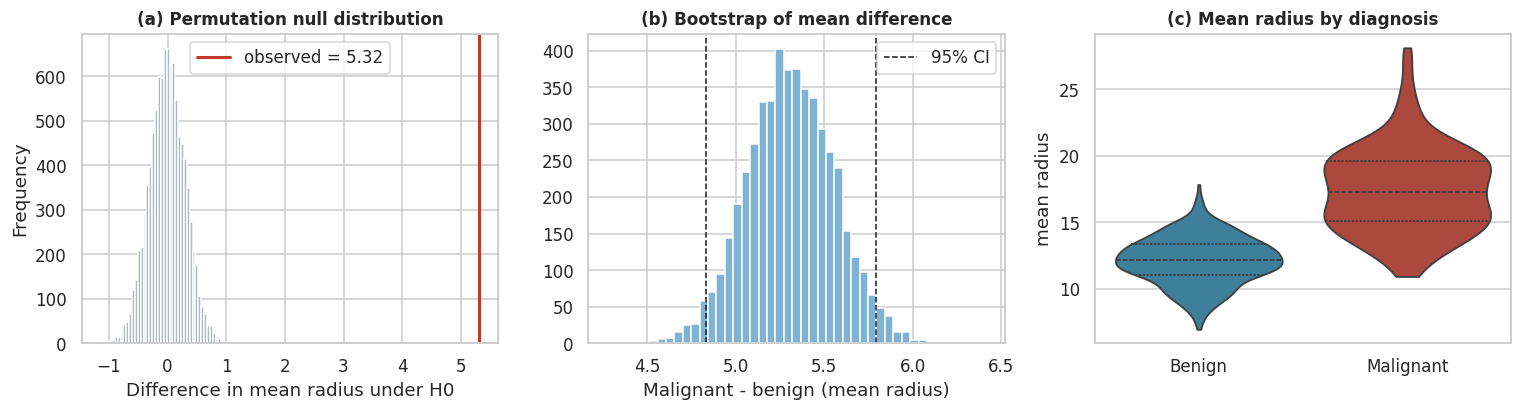

In [18]:
# Figure 3 - CDA visuals
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
ax[0].hist(perm_diffs, bins=45, color="#B0B7BF", edgecolor="white")
ax[0].axvline(diff, color=PAL["Malignant"], lw=2, label=f"observed = {diff:.2f}")
ax[0].set_title("(a) Permutation null distribution"); ax[0].set_xlabel("Difference in mean radius under H0"); ax[0].set_ylabel("Frequency"); ax[0].legend()
ax[1].hist(boot, bins=45, color="#7FB3D5", edgecolor="white")
ax[1].axvline(ci_b[0], color="k", ls="--", lw=1); ax[1].axvline(ci_b[1], color="k", ls="--", lw=1, label="95% CI")
ax[1].set_title("(b) Bootstrap of mean difference"); ax[1].set_xlabel("Malignant - benign (mean radius)"); ax[1].legend()
sns.violinplot(data=clean, x="diagnosis", y="mean radius", order=["Benign", "Malignant"], palette=PAL, inner="quartile", ax=ax[2], cut=0)
ax[2].set_title("(c) Mean radius by diagnosis"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig("figures/fig3_cda.png", dpi=200, bbox_inches="tight"); plt.show()

### 4.5 Interpretation
Because p ≪ 0.05 we **reject H₀**. Malignant masses have a significantly larger mean nucleus radius – by about 5.3 units (≈ 44% larger) – and the effect is very large (Cohen's d ≈ 2.2). The non-parametric, permutation and bootstrap results agree with the Welch test. The data are observational and come from one hospital programme, so this shows association, not that large nuclei cause malignancy.

## 5. CDA 2 – Is malignancy associated with boundary irregularity? (chi-square test of independence)
### 5.1 Research question and hypotheses
**Research question 2:** Is diagnosis (malignant / benign) statistically associated with the level of nuclear boundary irregularity, measured by *mean concave points* (**High** = above the sample median, **Low** = at or below)?

* **H₀:** diagnosis and irregularity level are independent.
* **H₁:** diagnosis and irregularity level are associated.
* **Significance level:** α = 0.05.

### 5.2 Choice of test
Both variables are categorical with two levels (a 2 × 2 table) and each mass appears once, so observations are independent: the **Pearson chi-square test of independence** is appropriate. We first check that all expected counts are at least 5, then confirm with **Fisher's exact test** and a **permutation test** (no large-sample assumption), and report the **odds ratio** and **phi** as effect sizes.

In [19]:
cut = clean["mean concave points"].median()
print(f"Median of mean concave points (cut-off): {cut:.4f}")
ct2 = pd.crosstab(clean["concavity_flag"], clean["diagnosis"]).loc[["High", "Low"], ["Malignant", "Benign"]]
print("Observed counts\n", ct2)

chi2_2, p_2, dof_2, exp_2 = stats.chi2_contingency(ct2, correction=False)
chi2_y, p_y, _, _ = stats.chi2_contingency(ct2, correction=True)
print("\nExpected counts under independence\n", pd.DataFrame(exp_2, index=ct2.index, columns=ct2.columns).round(2))
print(f"Minimum expected count = {exp_2.min():.1f} (>= 5, so the chi-square approximation is valid)")
print(f"\nPearson chi2(1) = {chi2_2:.2f}, p = {p_2:.3g}   |   with Yates correction: chi2 = {chi2_y:.2f}, p = {p_y:.3g}")

Median of mean concave points (cut-off): 0.0335
Observed counts
 diagnosis       Malignant  Benign
concavity_flag                   
High                  201      83
Low                    11     274

Expected counts under independence
 diagnosis       Malignant  Benign
concavity_flag                   
High               105.81  178.19
Low                106.19  178.81
Minimum expected count = 105.8 (>= 5, so the chi-square approximation is valid)

Pearson chi2(1) = 272.47, p = 3.29e-61   |   with Yates correction: chi2 = 269.61, p = 1.38e-60


In [20]:
a_, b_ = ct2.loc["High", "Malignant"], ct2.loc["High", "Benign"]
c_, d_ = ct2.loc["Low", "Malignant"], ct2.loc["Low", "Benign"]
n2 = ct2.values.sum()
phi = np.sqrt(chi2_2 / n2)
OR = (a_ * d_) / (b_ * c_)
se_lor = np.sqrt(1/a_ + 1/b_ + 1/c_ + 1/d_)
or_ci = np.exp(np.log(OR) + np.array([-1, 1]) * 1.96 * se_lor)
fisher = stats.fisher_exact(ct2.values)
p_hi, p_lo = a_/(a_+b_), c_/(c_+d_)
se_diff = np.sqrt(p_hi*(1-p_hi)/(a_+b_) + p_lo*(1-p_lo)/(c_+d_))
diff_ci = (p_hi - p_lo) + np.array([-1, 1]) * 1.96 * se_diff
print(f"Malignant share: High irregularity {100*p_hi:.1f}% ({a_}/{a_+b_}) vs Low {100*p_lo:.1f}% ({c_}/{c_+d_})")
print(f"Difference in proportions = {100*(p_hi-p_lo):.1f} points, 95% CI [{100*diff_ci[0]:.1f}, {100*diff_ci[1]:.1f}]")
print(f"Odds ratio = {OR:.1f}, 95% CI [{or_ci[0]:.1f}, {or_ci[1]:.1f}]  (Fisher exact conditional OR = {fisher[0]:.1f}, p = {fisher[1]:.3g})")
print(f"phi (= Cramer's V for 2x2) = {phi:.3f}")

# permutation test of the chi-square statistic (shuffle diagnosis labels)
hi_mask = (clean["concavity_flag"] == "High").values
y_m = (clean["diagnosis"] == "Malignant").values
def chi2_from_a(a_cnt):
    nh, nl, nm = hi_mask.sum(), (~hi_mask).sum(), y_m.sum()
    tab = np.array([[a_cnt, nh - a_cnt], [nm - a_cnt, nl - (nm - a_cnt)]])
    e = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
    return ((tab - e) ** 2 / e).sum()
Bp = 10000
perm_chi2 = np.empty(Bp)
for i in range(Bp):
    perm_chi2[i] = chi2_from_a(rng.permutation(y_m)[hi_mask].sum())
p_perm2 = (np.sum(perm_chi2 >= chi2_2) + 1) / (Bp + 1)
print(f"\nPermutation test ({Bp:,} shuffles): observed chi2 = {chi2_2:.1f}, largest shuffled chi2 = {perm_chi2.max():.1f}, p = {p_perm2:.4g}")
print("Decision at alpha = 0.05:", "REJECT H0" if p_2 < .05 else "FAIL TO REJECT H0")

Malignant share: High irregularity 70.8% (201/284) vs Low 3.9% (11/285)
Difference in proportions = 66.9 points, 95% CI [61.2, 72.7]
Odds ratio = 60.3, 95% CI [31.3, 116.1]  (Fisher exact conditional OR = 60.3, p = 7.38e-70)
phi (= Cramer's V for 2x2) = 0.692

Permutation test (10,000 shuffles): observed chi2 = 272.5, largest shuffled chi2 = 14.8, p = 9.999e-05
Decision at alpha = 0.05: REJECT H0


In [21]:
# Sensitivity of the conclusion to the cut-off (25th / 50th / 75th percentile of mean concave points)
rows = []
for q in [.25, .50, .75]:
    thr = clean["mean concave points"].quantile(q)
    hi = clean["mean concave points"] > thr
    t_ = pd.crosstab(hi, clean["diagnosis"]).reindex(index=[True, False], columns=["Malignant", "Benign"])
    c2, p_, _, _ = stats.chi2_contingency(t_, correction=False)
    ph, pl = t_.loc[True, "Malignant"]/t_.loc[True].sum(), t_.loc[False, "Malignant"]/t_.loc[False].sum()
    orr = (t_.loc[True, "Malignant"]*t_.loc[False, "Benign"])/(t_.loc[True, "Benign"]*t_.loc[False, "Malignant"])
    rows.append([f"{int(q*100)}th pct ({thr:.4f})", int(t_.loc[True].sum()), round(100*ph, 1), round(100*pl, 1), round(orr, 1), round(c2, 1), f"{p_:.1e}"])
sens = pd.DataFrame(rows, columns=["Cut-off", "n High", "% malignant High", "% malignant Low", "Odds ratio", "chi2(1)", "p"])
sens

,Cut-off,n High,% malignant High,% malignant Low,Odds ratio,chi2(1),p
0,25th pct (0.0203),426,49.5,0.7,139.4,109.2,1.5e-25
1,50th pct (0.0335),284,70.8,3.9,60.3,272.5,3.3e-61
2,75th pct (0.0740),142,97.2,17.3,164.6,290.7,3.5e-65


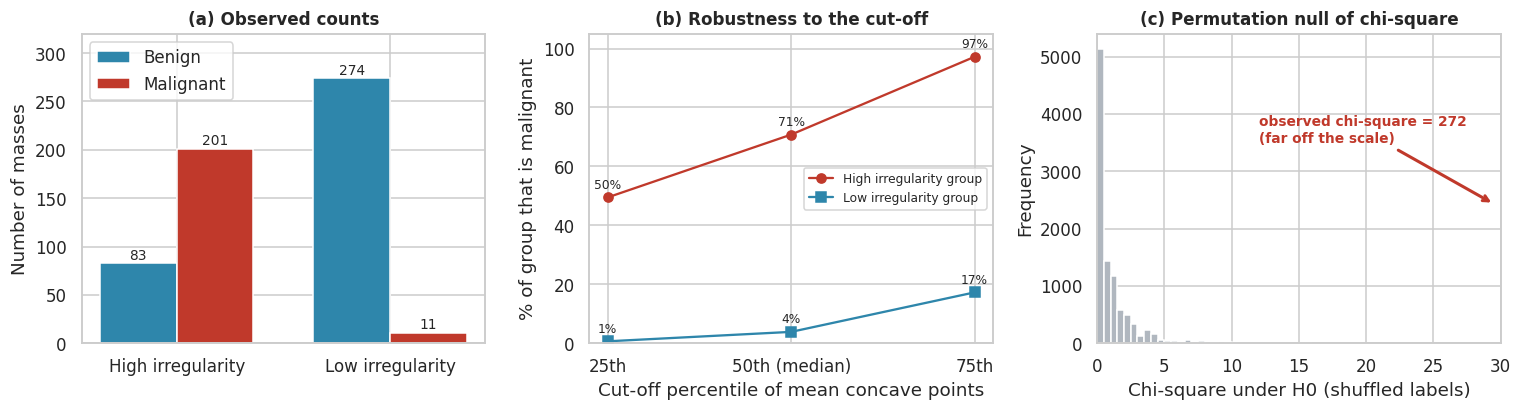

In [22]:
# Figure 4 - CDA 2 visuals
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
w = .36; xs = np.arange(2)
ax[0].bar(xs - w/2, ct2["Benign"].values, w, color=PAL["Benign"], label="Benign")
ax[0].bar(xs + w/2, ct2["Malignant"].values, w, color=PAL["Malignant"], label="Malignant")
for x_, v_ in zip(xs - w/2, ct2["Benign"].values): ax[0].text(x_, v_ + 4, str(v_), ha="center", fontsize=9)
for x_, v_ in zip(xs + w/2, ct2["Malignant"].values): ax[0].text(x_, v_ + 4, str(v_), ha="center", fontsize=9)
ax[0].set_xticks(xs); ax[0].set_xticklabels(["High irregularity", "Low irregularity"]); ax[0].set_ylabel("Number of masses"); ax[0].set_ylim(0, 320)
ax[0].set_title("(a) Observed counts"); ax[0].legend()

pct = [25, 50, 75]; hi_r = [r[2] for r in rows]; lo_r = [r[3] for r in rows]
ax[1].plot(pct, hi_r, "o-", color=PAL["Malignant"], label="High irregularity group")
ax[1].plot(pct, lo_r, "s-", color=PAL["Benign"], label="Low irregularity group")
for x_, h_, l_ in zip(pct, hi_r, lo_r): ax[1].text(x_, h_ + 3, f"{h_:.0f}%", ha="center", fontsize=8); ax[1].text(x_, l_ + 3, f"{l_:.0f}%", ha="center", fontsize=8)
ax[1].set_xticks(pct); ax[1].set_xticklabels(["25th", "50th (median)", "75th"]); ax[1].set_ylim(0, 105)
ax[1].set_xlabel("Cut-off percentile of mean concave points"); ax[1].set_ylabel("% of group that is malignant"); ax[1].set_title("(b) Robustness to the cut-off"); ax[1].legend(loc="center right", fontsize=8)

ax[2].hist(perm_chi2, bins=np.linspace(0, 16, 33), color="#B0B7BF", edgecolor="white")
ax[2].set_xlim(0, 30)
ax[2].annotate(f"observed chi-square = {chi2_2:.0f}\n(far off the scale)", xy=(29.5, ax[2].get_ylim()[1]*0.45), xytext=(12, ax[2].get_ylim()[1]*0.65),
               arrowprops=dict(arrowstyle="->", color=PAL["Malignant"], lw=2), color=PAL["Malignant"], fontsize=9, fontweight="bold")
ax[2].set_title("(c) Permutation null of chi-square"); ax[2].set_xlabel("Chi-square under H0 (shuffled labels)"); ax[2].set_ylabel("Frequency")
plt.tight_layout(); plt.savefig("figures/fig4_cda2.png", dpi=200, bbox_inches="tight"); plt.show()

### 5.3 Interpretation
Since p ≪ 0.05 we **reject H₀**: diagnosis and boundary irregularity are strongly associated. Masses with high irregularity are malignant far more often than those with low irregularity (about 71% versus 4%), the odds ratio is very large, and the result is the same under Yates' correction, Fisher's exact test, a permutation test and at the 25th and 75th percentile cut-offs. The association is observational and the median cut-off is data-driven, so this describes a pattern in this sample and is not a causal or clinical rule.

## 6. Supporting analyses
### 6.1 Which nucleus features separate the classes? (multiple testing with Holm correction)

In [23]:
rows = []
for c in X.columns:
    x1, x0 = mal[c].values, ben[c].values
    t_ = stats.ttest_ind(x1, x0, equal_var=False)
    u_ = stats.mannwhitneyu(x1, x0, alternative="two-sided")
    rows.append([c, x1.mean(), x0.mean(), t_.statistic, t_.pvalue, u_.pvalue, cohens_d(mal[c], ben[c])])
res = pd.DataFrame(rows, columns=["feature", "mean_malignant", "mean_benign", "welch_t", "p_welch", "p_mwu", "cohens_d"])
# Holm step-down adjustment over 30 tests
order = res["p_welch"].argsort().values; m_ = len(res); adj = np.empty(m_); running = 0
for rank, idx in enumerate(order):
    running = max(running, (m_ - rank) * res.loc[idx, "p_welch"]); adj[idx] = min(1, running)
res["p_holm"] = adj
res["significant_after_holm"] = res["p_holm"] < .05
res = res.reindex(res["cohens_d"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print("Significant after Holm correction (alpha = .05):", int(res.significant_after_holm.sum()), "of 30")
print("Not significant:", res.loc[~res.significant_after_holm, "feature"].tolist())
show = res.head(10).copy()
for c_ in ["p_welch", "p_mwu", "p_holm"]: show[c_] = show[c_].map(lambda v: f"{v:.1e}")
show.round(3)

Significant after Holm correction (alpha = .05): 25 of 30
Not significant: ['fractal dimension error', 'smoothness error', 'mean fractal dimension', 'texture error', 'symmetry error']


,feature,mean_malignant,mean_benign,welch_t,p_welch,p_mwu,cohens_d,p_holm,significant_after_holm
0,worst concave points,0.182,0.074,29.118,1.1e-96,1.9e-77,2.693,3.2e-95,True
1,worst perimeter,141.370,87.006,25.332,1.0e-72,2.6e-80,2.598,3.0e-71,True
2,mean concave points,0.088,0.026,24.845,3.1e-71,1.0e-76,2.545,8.8e-70,True
3,worst radius,21.135,13.380,24.830,3.6e-71,1.1e-78,2.544,9.6e-70,True
4,mean perimeter,115.365,78.075,22.935,1.0e-66,3.6e-71,2.290,2.7e-65,True
5,worst area,1422.286,558.899,20.571,4.9e-54,1.8e-78,2.230,1.1e-52,True
6,mean radius,17.463,12.147,22.209,1.7e-64,2.7e-68,2.205,4.2e-63,True
7,mean area,978.376,462.790,19.641,3.3e-52,1.5e-68,2.076,6.9e-51,True
8,mean concavity,0.161,0.046,20.332,3.7e-58,2.2e-68,2.003,8.6e-57,True
9,worst concavity,0.451,0.166,19.596,9.9e-59,1.8e-63,1.812,2.4e-57,True


### 6.2 Predictive check: how well do the features discriminate? (5-fold stratified CV)

In [24]:
y = clean["is_malignant"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Radius only": (clean[["mean radius"]], make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "Radius + concave points": (clean[["mean radius", "mean concave points"]], make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "All 30 features": (X, make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=1.0))),
}
out = []
for name, (Xm, mdl) in models.items():
    prob = cross_val_predict(mdl, Xm, y, cv=cv, method="predict_proba")[:, 1]
    pred = (prob > .5).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    out.append([name, roc_auc_score(y, prob), accuracy_score(y, pred), tp/(tp+fn), tn/(tn+fp)])
perf = pd.DataFrame(out, columns=["Model", "CV AUC", "Accuracy", "Sensitivity (malignant)", "Specificity (benign)"]).round(3)
perf

,Model,CV AUC,Accuracy,Sensitivity (malignant),Specificity (benign)
0,Radius only,0.935,0.880,0.788,0.936
1,Radius + concave points,0.976,0.909,0.849,0.944
2,All 30 features,0.995,0.974,0.943,0.992


## 7. Findings and conclusion
* **CDA 1:** Mean nucleus radius differs strongly between malignant and benign masses (Welch t, p < 0.0001, d ≈ 2.2); the rank-based, permutation and bootstrap checks agree.
* **CDA 2:** Diagnosis is strongly associated with boundary irregularity (chi-square, χ²(1) = 272.5, p < 0.0001, φ = 0.69): 70.8% of high-irregularity masses are malignant versus 3.9% of low-irregularity masses (odds ratio ≈ 60); Fisher's exact test, a permutation test and other cut-offs agree.
* Size and irregularity (concave points, concavity) are the strongest separators; after Holm correction 25 of 30 features differ significantly, while texture-error, symmetry-error and fractal-dimension features carry almost no signal.
* A simple logistic model on radius and concave points already reaches a cross-validated AUC above 0.97; all 30 features reach about 0.995, consistent with the visible separation in PCA.
* **Limitations:** observational data from one programme (1990s Wisconsin), 569 masses, no patient IDs (repeat patients cannot be excluded), highly collinear features, a data-driven median cut-off for CDA 2, and image-derived measurements that depend on segmentation. Results describe association and screening support, not a clinical decision rule.
* **Future work:** external validation on newer imaging data, regularised or tree-based models with calibration, and cost-sensitive thresholds that favour sensitivity.